# Emotional Framing on Netflix. A Lexicon-Based Analysis of Content Types, Genres and Catalogue Trends

Author: Kristian Roncero

In this project I will be working on the dataset of Netflix releases and the emotional profiles of the descriptions and comments based on sentiment analysis. 


## 1. Setup: loading the libraries

I start by importing the libraries.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt

## 2. Context and questions

The approach is simple: for each title, I extract words from the description that appear in the lexicon, sum their emotion scores, and attach the result back to the Netflix dataframe.
The key question to ask is the following

>How do normalized emotion profiles in Netflix title descriptions differ between: movies and TV Shows and major genre families?; and how did the emotional framing of titles added to Netflix change from 2017 to 2020?

## 3. Data gathering

I will use two datasets:
- **`netflix_titles.csv`** — metadata for ~8,800 Netflix titles including a short description of each
- **`emotion_lexicon.csv`** — the [NRC Emotion Lexicon](https://saifmohammad.com/WebPages/NRC-Emotion-Lexicon.htm), which maps words to eight basic emotions (Plutchik's wheel) and three VAD dimensions (Valence, Arousal, Dominance).
  
[N.B.] For the scope of this project I will probably disregard the file including major events in the 21st century, because it may add more noise and/or make the analysis more complicated at this point.

In [2]:
emotion_lexicon = pd.read_csv('emotion_lexicon.csv')
netflix = pd.read_csv('netflix_titles.csv')

## 4. Data examination and audit
### 4.1. Initial inspection

In [3]:
print(f"Emotion lexicon: {emotion_lexicon.shape[0]:,} words, {emotion_lexicon.shape[1]} columns")
emotion_lexicon.head(10)

Emotion lexicon: 19,971 words, 23 columns


,word,NRC_EmoLex_anger,NRC_EmoLex_anticipation,NRC_EmoLex_disgust,NRC_EmoLex_fear,NRC_EmoLex_joy,NRC_EmoLex_negative,NRC_EmoLex_positive,NRC_EmoLex_sadness,NRC_EmoLex_surprise,...,NRC_VAD_arousal_low,NRC_VAD_arousal_polar,NRC_VAD_dominance,NRC_VAD_dominance_high,NRC_VAD_dominance_low,NRC_VAD_dominance_polar,NRC_VAD_valence,NRC_VAD_valence_high,NRC_VAD_valence_low,NRC_VAD_valence_polar
0,aaaaaaah,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.291,0.0,0.291,0.291,0.479,0.0,0.000,0.000
1,aaaah,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.282,0.0,0.282,0.282,0.520,0.0,0.000,0.000
2,aardvark,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.437,0.0,0.000,0.000,0.427,0.0,0.000,0.000
3,aback,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.288,0.0,0.288,0.288,0.385,0.0,0.000,0.000
4,abacus,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.276,0.276,0.485,0.0,0.000,0.000,0.510,0.0,0.000,0.000
5,abalone,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.412,0.0,0.000,0.000,0.500,0.0,0.000,0.000
6,abandon,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.000,0.000,0.245,0.0,0.245,0.245,0.052,0.0,0.052,0.052
7,abandoned,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.000,0.000,0.130,0.0,0.130,0.130,0.046,0.0,0.046,0.046
8,abandonment,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.000,0.000,0.202,0.0,0.202,0.202,0.128,0.0,0.128,0.128
9,abashed,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.000,0.000,0.307,0.0,0.307,0.307,0.177,0.0,0.177,0.177


In [4]:
emotion_lexicon.info

<bound method DataFrame.info of              word  NRC_EmoLex_anger  NRC_EmoLex_anticipation  \
0        aaaaaaah               0.0                      0.0   
1           aaaah               0.0                      0.0   
2        aardvark               0.0                      0.0   
3           aback               0.0                      0.0   
4          abacus               0.0                      0.0   
...           ...               ...                      ...   
19966  zoological               0.0                      0.0   
19967     zoology               0.0                      0.0   
19968        zoom               0.0                      0.0   
19969    zucchini               0.0                      0.0   
19970           0               0.0                      0.0   

       NRC_EmoLex_disgust  NRC_EmoLex_fear  NRC_EmoLex_joy  \
0                     0.0              0.0             0.0   
1                     0.0              0.0             0.0   
2            

In [5]:
emotion_lexicon.dtypes

word                           str
NRC_EmoLex_anger           float64
NRC_EmoLex_anticipation    float64
NRC_EmoLex_disgust         float64
NRC_EmoLex_fear            float64
NRC_EmoLex_joy             float64
NRC_EmoLex_negative        float64
NRC_EmoLex_positive        float64
NRC_EmoLex_sadness         float64
NRC_EmoLex_surprise        float64
NRC_EmoLex_trust           float64
NRC_VAD_arousal            float64
NRC_VAD_arousal_high       float64
NRC_VAD_arousal_low        float64
NRC_VAD_arousal_polar      float64
NRC_VAD_dominance          float64
NRC_VAD_dominance_high     float64
NRC_VAD_dominance_low      float64
NRC_VAD_dominance_polar    float64
NRC_VAD_valence            float64
NRC_VAD_valence_high       float64
NRC_VAD_valence_low        float64
NRC_VAD_valence_polar      float64
dtype: object

In [6]:
print(f"Netflix titles: {netflix.shape[0]:,} rows, {netflix.shape[1]} columns")
netflix.head(10)

Netflix titles: 8,807 rows, 12 columns


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
5,s6,TV Show,Midnight Mass,Mike Flanagan,"Kate Siegel, Zach Gilford, Hamish Linklater, H...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",The arrival of a charismatic young priest brin...
6,s7,Movie,My Little Pony: A New Generation,"Robert Cullen, José Luis Ucha","Vanessa Hudgens, Kimiko Glenn, James Marsden, ...",NaN,"September 24, 2021",2021,PG,91 min,Children & Family Movies,Equestria's divided. But a bright-eyed hero be...
7,s8,Movie,Sankofa,Haile Gerima,"Kofi Ghanaba, Oyafunmike Ogunlano, Alexandra D...","United States, Ghana, Burkina Faso, United Kin...","September 24, 2021",1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies","On a photo shoot in Ghana, an American model s..."
8,s9,TV Show,The Great British Baking Show,Andy Devonshire,"Mel Giedroyc, Sue Perkins, Mary Berry, Paul Ho...",United Kingdom,"September 24, 2021",2021,TV-14,9 Seasons,"British TV Shows, Reality TV",A talented batch of amateur bakers face off in...
9,s10,Movie,The Starling,Theodore Melfi,"Melissa McCarthy, Chris O'Dowd, Kevin Kline, T...",United States,"September 24, 2021",2021,PG-13,104 min,"Comedies, Dramas",A woman adjusting to life after a loss contend...


In [7]:
netflix.info

<bound method DataFrame.info of      show_id     type                  title         director  \
0         s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1         s2  TV Show          Blood & Water              NaN   
2         s3  TV Show              Ganglands  Julien Leclercq   
3         s4  TV Show  Jailbirds New Orleans              NaN   
4         s5  TV Show           Kota Factory              NaN   
...      ...      ...                    ...              ...   
8802   s8803    Movie                 Zodiac    David Fincher   
8803   s8804  TV Show            Zombie Dumb              NaN   
8804   s8805    Movie             Zombieland  Ruben Fleischer   
8805   s8806    Movie                   Zoom     Peter Hewitt   
8806   s8807    Movie                 Zubaan      Mozez Singh   

                                                   cast        country  \
0                                                   NaN  United States   
1     Ama Qamata, Khosi Ngema, Gail Mab

In [8]:
netflix.dtypes

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object

The data for emotional_analysis looks stable/clean; however the Netflix data contains some missing values and I have spotted something fishy on the columns. `release_year`  is stored as  <int64>, whereas `date_added` as a  <str>. Given that they are just years and not full dates, I think it makes more sense to convert both to <int64>. Let's check the structure of the dates to be on the safe side.

In [9]:
netflix["date_added"].head()

0    September 25, 2021
1    September 24, 2021
2    September 24, 2021
3    September 24, 2021
4    September 24, 2021
Name: date_added, dtype: str

### 4.2. Data Quality Audit

#### 4.2.1. Missing values
I will inspect which columns are missing what and how much. The most important column is the description, so I may have to flag all the records missing on from future analyses.

In [10]:
netflix_missing = (
    netflix.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

netflix_missing["missing_pct"] = (
    netflix_missing["missing_values"] / len(netflix) * 100
).round(2)

netflix_missing

,missing_values,missing_pct
director,2634,29.91
country,831,9.44
cast,825,9.37
date_added,10,0.11
rating,4,0.05
duration,3,0.03
show_id,0,0.00
type,0,0.00
title,0,0.00
release_year,0,0.00


Thankfully, two of the most important columns are all full: show_id, which will be our key to search for duplicates (as there may be films with the same title just released in different years, or some series may get messy, with titles repeating multiple times with the same director/release_year etc.); description (our core data). release_year is also complete, but for this analysis it will not play a major role, I belive it is more interesting to see when the films were added into the platform; i.e. date_added, which is almost complete, though not perfect.

It is striking to see how often the directors are missing from the dataset (% 29.91) and the country of origin (% 9.44) and cast (% 9.37). They could give us some regional preferences or show if films by a specific director or actor/actress on them score differently in our scale.
**So I have to acknowledge the limitation for this study.** 

In [11]:
emotion_lexicon.isna().sum()

word                       0
NRC_EmoLex_anger           0
NRC_EmoLex_anticipation    0
NRC_EmoLex_disgust         0
NRC_EmoLex_fear            0
NRC_EmoLex_joy             0
NRC_EmoLex_negative        0
NRC_EmoLex_positive        0
NRC_EmoLex_sadness         0
NRC_EmoLex_surprise        0
NRC_EmoLex_trust           0
NRC_VAD_arousal            0
NRC_VAD_arousal_high       0
NRC_VAD_arousal_low        0
NRC_VAD_arousal_polar      0
NRC_VAD_dominance          0
NRC_VAD_dominance_high     0
NRC_VAD_dominance_low      0
NRC_VAD_dominance_polar    0
NRC_VAD_valence            0
NRC_VAD_valence_high       0
NRC_VAD_valence_low        0
NRC_VAD_valence_polar      0
dtype: int64

There are **no missing values** in the emotional_analysis document.

#### 4.2.2. Duplicates and identifiers

As previously stated, the show_id should play as our main key to search for duplicates. The lexicon also should include a single record for each entry, even though they may look the same (e.g."*aaaaah*" is not the same as "*aaah*").

In [12]:
print("Duplicate Netflix rows:", netflix.duplicated().sum())
print("Duplicate show IDs:", netflix["show_id"].duplicated().sum())

print("Duplicate lexicon rows:", emotion_lexicon.duplicated().sum())
print("Duplicate lexicon words:", emotion_lexicon["word"].duplicated().sum())

if (netflix.duplicated().sum() == 0 and 
    netflix["show_id"].duplicated().sum() == 0 and 
    emotion_lexicon.duplicated().sum() == 0 and 
    emotion_lexicon["word"].duplicated().sum() == 0):
    print("Way to go, you can move on!")

Duplicate Netflix rows: 0
Duplicate show IDs: 0
Duplicate lexicon rows: 0
Duplicate lexicon words: 0
Way to go, you can move on!


#### 4.2.2.1. Netflix dataset audit
Let's check the consistency of the data types that are relevant for the study, namely the genre (`listed_in`), `type` (e.g. series) and `rating` (PG, +13, etc).

In [13]:
print(netflix["listed_in"].value_counts())

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
                                                   ... 
Comedies, Cult Movies, LGBTQ Movies                   1
Action & Adventure, Comedies, Horror Movies           1
Classic & Cult TV, Crime TV Shows, TV Dramas          1
Action & Adventure, Documentaries, Sports Movies      1
Cult Movies, Dramas, Thrillers                        1
Name: count, Length: 514, dtype: int64


A first quick look at the listed_in column shows that data are quite messy over here. For example, dramas appear in at least 3 categories, documentaries twice, and stand-up-comedy is treated separately, while comedies appear other 3 times. One of the first steps for normalisation will be splitting the comma-separated labels rather than treating every full listed_in value as a genre.

In [14]:
print(netflix["type"].value_counts())

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


There is a predominance of movies to tv show (roughly 3:1).

In [15]:
print(netflix["rating"].value_counts())

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


There is a small inconsistency with the rating. Three lengths are listed as rating (which may explain the missing duration for 3 films in the previous step).
Also there is a mixture of systems which probably is country specific. So data need to either be normalised and standardised or this section can be excluded from the analysis.

##### 4.2.2.2 Netflix dataset audit flags

I will start by selecting the subset of columns for our analysis and flag those who have a missing or unusual value.

In [16]:
analysis_cols = [
    "show_id",
    "type",
    "title",
    "date_added",
    "release_year",
    "listed_in",
    "description"
]

netflix[analysis_cols].head()

,show_id,type,title,date_added,release_year,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,"September 25, 2021",2020,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,"September 24, 2021",2021,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,"September 24, 2021",2021,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,"September 24, 2021",2021,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,"September 24, 2021",2021,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [17]:
netflix[analysis_cols].isna().sum()

show_id          0
type             0
title            0
date_added      10
release_year     0
listed_in        0
description      0
dtype: int64

The only column missing data is `date_added`. I will inspect those 10 records and see what can be done and then flag them. 

In [18]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

missing_date_added = netflix[netflix["date_added"].isna()][analysis_cols]
print(f"Records with missing data: {len(missing_date_added)}")
missing_date_added

Records with missing data: 10


,show_id,type,title,date_added,release_year,listed_in,description
6066,s6067,TV Show,A Young Doctor's Notebook and Other Stories,NaN,2013,"British TV Shows, TV Comedies, TV Dramas","Set during the Russian Revolution, this comic miniseries is based on a doctor's memories of his early career working in an out-of-the-way village."
6174,s6175,TV Show,Anthony Bourdain: Parts Unknown,NaN,2018,Docuseries,This CNN original series has chef Anthony Bourdain traveling to extraordinary locations around the globe to sample a variety of local cuisines.
6795,s6796,TV Show,Frasier,NaN,2003,"Classic & Cult TV, TV Comedies",Frasier Crane is a snooty but lovable Seattle psychiatrist who dispenses advice on his call-in radio show while ignoring it in his own relationships.
6806,s6807,TV Show,Friends,NaN,2003,"Classic & Cult TV, TV Comedies","This hit sitcom follows the merry misadventures of six 20-something pals as they navigate the pitfalls of work, life and love in 1990s Manhattan."
6901,s6902,TV Show,Gunslinger Girl,NaN,2008,"Anime Series, Crime TV Shows","On the surface, the Social Welfare Agency appears to help orphaned schoolgirls, but it's actually turning them into lethal agents."
7196,s7197,TV Show,Kikoriki,NaN,2010,Kids' TV,"A wacky rabbit and his gang of animal pals have fun solving problems, sharing stories and exploring their sometimes magical, always special world."
7254,s7255,TV Show,La Familia P. Luche,NaN,2012,"International TV Shows, Spanish-Language TV Shows, TV Comedies","This irreverent sitcom featues Ludovico, Federica and their three children Bibi, Junior and Ludoviquito, living in Ciudad P. Luche."
7406,s7407,TV Show,Maron,NaN,2016,TV Comedies,"Marc Maron stars as Marc Maron, who interviews fellow comedians for his popular podcast, only to reveal more about his own neuroses and relationships."
7847,s7848,TV Show,Red vs. Blue,NaN,2015,"TV Action & Adventure, TV Comedies, TV Sci-Fi & Fantasy","This parody of first-person shooter games, military life and science-fiction films centers on a civil war fought in the middle of a desolate canyon."
8182,s8183,TV Show,The Adventures of Figaro Pho,NaN,2015,"Kids' TV, TV Comedies","Imagine your worst fears, then multiply them: Figaro is a boy with any number of phobias and a highly quirky and imaginative way of dealing with them."


In [19]:
netflix["date_added"].max(),netflix["date_added"].min()

('September 9, 2021', ' April 15, 2018')

This is an important issue to flag. The data in **the study only cover titles added between April 15, 2018 and September 9, 2021**. All the titles without a date for when they got uploaded to Netflix were released before 2018, except for `film_id 6174`, which was released in 2018 (not sure if it was added before the period cover in this study or afterwards). Should a title had been released after 2018 or 2020, it would have been safer to calculate the date_added, but at the moment, we can only flag these and exclude them from further analyses. Also data here has full `mm.dd.yyyy format`, whereas for this study we will only have time to compare the years. We will need to extract the year at a further step. 

In [20]:
netflix["flag_date"] = netflix["date_added"].isna()
print(f"Rows with missing date_added (flag_date = True): {netflix['flag_date'].sum()}")

Rows with missing date_added (flag_date = True): 10


Given that the text of the descriptions is the main object of study, I want to quickly check if it is more or less consistent. I want to inspect the average wordcount for each description, the median, the minimum and the maximum.


In [21]:
 #With the help of ChatGPT and REXs let us first create a column that counts the wordcount.

netflix["description_word_count"] = (
    netflix["description"]
    .str.findall(r"\b[\w’'-]+\b")
    .str.len()
)

netflix["description_word_count"]

0       27
1       27
2       27
3       24
4       24
5       23
6       24
7       28
8       28
9       28
10      23
11      22
12      25
13      26
14      23
15      25
16      24
17      25
18      25
19      24
20      22
21      24
22      25
23      27
24      29
25      24
26      30
27      26
28      24
29      20
30      24
31      22
32      25
33      22
34      22
35      26
36      28
37      24
38      26
39      22
40      24
41      24
42      22
43      29
44      26
45      26
46      27
47      21
48      26
49      22
50      21
51      25
52      30
53      24
54      25
55      26
56      23
57      23
58      25
59      25
60      29
61      24
62      24
63      25
64      25
65      23
66      19
67      27
68      19
69      20
70      27
71      22
72      23
73      20
74      25
75      24
76      25
77      27
78      24
79      24
80      27
81      29
82      26
83      27
84      26
85      25
86      23
87      26
88      24
89      26
90      26

In [22]:
min_word_length = netflix["description_word_count"].min()
max_word_length = netflix["description_word_count"].max()
median_word_length = netflix["description_word_count"].median()
avg_word_length = netflix["description_word_count"].mean()

print(f"Shortest comment: {min_word_length} words")
print(f"Longest comment: {max_word_length} words")
print(f"Median comment length: {median_word_length} words")
print(f"Average comment length: {avg_word_length} words")

Shortest comment: 10 words
Longest comment: 47 words
Median comment length: 24.0 words
Average comment length: 23.80810718746452 words


There is a huge gap between the extremes, just to avoid problems in the future, I want to calculate the percentage of comments within the Q1 and Q3.

Q1 (25th percentile): 22.0 words
Q3 (75th percentile): 26.0 words
IQR (Interquartile Range): 4.0 words

Outlier bounds:
  Lower bound: 16.0 words
  Upper bound: 32.0 words

Percentage of comments within Q1-Q3: 66.06%
Percentage of outliers: 0.69%


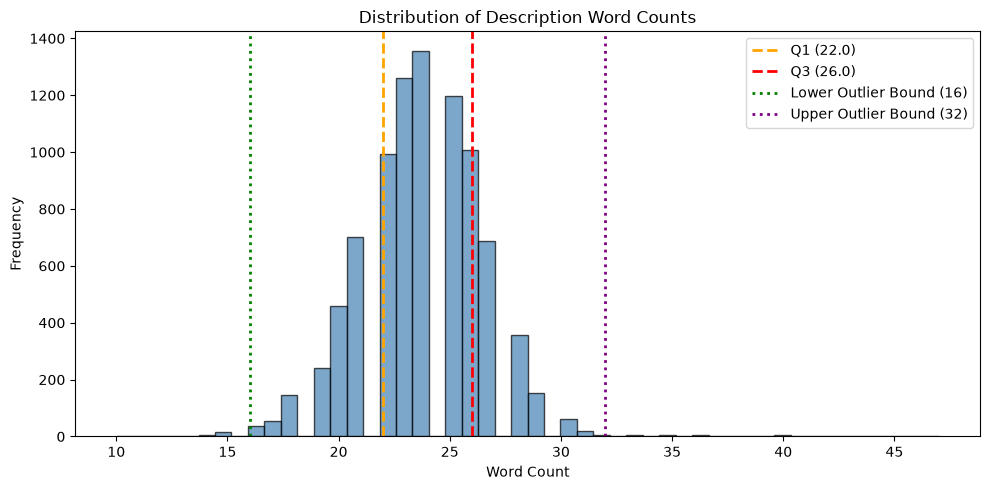

In [23]:
# Calculate quartiles and outliers
Q1 = netflix["description_word_count"].quantile(0.25)
Q3 = netflix["description_word_count"].quantile(0.75)
IQR = Q3 - Q1

# Define outliers using IQR method
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Calculate percentages
within_q1_q3 = ((netflix["description_word_count"] >= Q1) & (netflix["description_word_count"] <= Q3)).sum()
pct_within_q1_q3 = (within_q1_q3 / len(netflix)) * 100

outliers = ((netflix["description_word_count"] < lower_bound) | (netflix["description_word_count"] > upper_bound)).sum()
pct_outliers = (outliers / len(netflix)) * 100

print(f"Q1 (25th percentile): {Q1} words")
print(f"Q3 (75th percentile): {Q3} words")
print(f"IQR (Interquartile Range): {IQR} words")
print(f"\nOutlier bounds:")
print(f"  Lower bound: {lower_bound} words")
print(f"  Upper bound: {upper_bound} words")
print(f"\nPercentage of comments within Q1-Q3: {pct_within_q1_q3:.2f}%")
print(f"Percentage of outliers: {pct_outliers:.2f}%")

# Create histogram
plt.figure(figsize=(10, 5))
plt.hist(netflix["description_word_count"], bins=50, edgecolor='black', alpha=0.7, color='steelblue')
plt.axvline(Q1, color='orange', linestyle='--', linewidth=2, label=f'Q1 ({Q1})')
plt.axvline(Q3, color='red', linestyle='--', linewidth=2, label=f'Q3 ({Q3})')
plt.axvline(lower_bound, color='green', linestyle=':', linewidth=2, label=f'Lower Outlier Bound ({lower_bound:.0f})')
plt.axvline(upper_bound, color='purple', linestyle=':', linewidth=2, label=f'Upper Outlier Bound ({upper_bound:.0f})')
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.title('Distribution of Description Word Counts')
plt.legend()
plt.tight_layout()
plt.show()

Even though with natural language many irregularities are expected, the data distribution seems well represented between the lower outlier (16 words) and the upper outlier (32). Any description containing 10-12 words or less would be a lot hard to provide meaningful results, at the risk of skewing data. On the other hand, we have to be careful with the analysis, as double word count means double chances for emotional words and altering the score. Hence, in the future, I will probably have to assign scores with percentages rather than total word counts.

###### 4.2.2.3. Lexicon duplicates and audit
The key for this dataset are the words. In the previous subheading (4.2.1) we had seen that there were no obvious duplicated rows, but there may be repetitions in words, spelling inconsistencies or capitalisation issues which could hinder a further analysis. Let's start by inspecting them.

In [24]:
emotion_lexicon["word"].describe()

count        19971
unique       19971
top       aaaaaaah
freq             1
Name: word, dtype: object

In [25]:
print(
    "Duplicate words:",
    emotion_lexicon["word"].duplicated().sum()
)

print(
    "Words with extra whitespace:",
    (emotion_lexicon["word"] != emotion_lexicon["word"].str.strip()).sum()
)

print(
    "Words containing uppercase characters:",
    (emotion_lexicon["word"] != emotion_lexicon["word"].str.lower()).sum()
)

Duplicate words: 0
Words with extra whitespace: 0
Words containing uppercase characters: 0


This dataset seems spotless clean, but I will still be cautious. 

###### 4.2.2.4. Lexicon data audit

On my next step I want to define the columns from the lexicon that would be useful for the analysis, guided by ChatGPT 5.6. and see what there is to be flagged, by looking at their content and uniqueness.

In [26]:
emotion_cols = [
    "NRC_EmoLex_anger",
    "NRC_EmoLex_anticipation",
    "NRC_EmoLex_disgust",
    "NRC_EmoLex_fear",
    "NRC_EmoLex_joy",
    "NRC_EmoLex_sadness",
    "NRC_EmoLex_surprise",
    "NRC_EmoLex_trust"
]
emotion_lexicon[emotion_cols].describe()

,NRC_EmoLex_anger,NRC_EmoLex_anticipation,NRC_EmoLex_disgust,NRC_EmoLex_fear,NRC_EmoLex_joy,NRC_EmoLex_sadness,NRC_EmoLex_surprise,NRC_EmoLex_trust
count,19971.000000,19971.000000,19971.000000,19971.000000,19971.000000,19971.000000,19971.000000,19971.000000
mean,0.062340,0.041911,0.052877,0.073807,0.034400,0.059436,0.026639,0.061589
std,0.241779,0.200390,0.223793,0.261463,0.182259,0.236445,0.161029,0.240414
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [27]:
# Checking their uniqueness.

for col in emotion_cols:
    print(col, emotion_lexicon[col].unique())

NRC_EmoLex_anger [0. 1.]
NRC_EmoLex_anticipation [0. 1.]
NRC_EmoLex_disgust [0. 1.]
NRC_EmoLex_fear [0. 1.]
NRC_EmoLex_joy [0. 1.]
NRC_EmoLex_sadness [0. 1.]
NRC_EmoLex_surprise [0. 1.]
NRC_EmoLex_trust [0. 1.]


There are no surprises, all the data contain either "0" or "1".

In [28]:
vad_cols = [
    "NRC_VAD_valence",
    "NRC_VAD_arousal",
    "NRC_VAD_dominance"
]
emotion_lexicon[vad_cols].describe()

,NRC_VAD_valence,NRC_VAD_arousal,NRC_VAD_dominance
count,19971.000000,19971.000000,19971.000000
mean,0.500015,0.500002,0.500208
std,0.215699,0.171071,0.169900
min,0.000000,0.046000,0.045000
25%,0.347000,0.375000,0.375000
50%,0.510000,0.480000,0.482000
75%,0.653000,0.612000,0.620000
max,1.000000,0.990000,0.991000


They seem to contain continuous data/decimal numbers, but it all seems well structured. I will do a last quick data type inspection that I should have done earlier.

In [29]:
emotion_lexicon.dtypes

word                           str
NRC_EmoLex_anger           float64
NRC_EmoLex_anticipation    float64
NRC_EmoLex_disgust         float64
NRC_EmoLex_fear            float64
NRC_EmoLex_joy             float64
NRC_EmoLex_negative        float64
NRC_EmoLex_positive        float64
NRC_EmoLex_sadness         float64
NRC_EmoLex_surprise        float64
NRC_EmoLex_trust           float64
NRC_VAD_arousal            float64
NRC_VAD_arousal_high       float64
NRC_VAD_arousal_low        float64
NRC_VAD_arousal_polar      float64
NRC_VAD_dominance          float64
NRC_VAD_dominance_high     float64
NRC_VAD_dominance_low      float64
NRC_VAD_dominance_polar    float64
NRC_VAD_valence            float64
NRC_VAD_valence_high       float64
NRC_VAD_valence_low        float64
NRC_VAD_valence_polar      float64
dtype: object

So we will need to convert the emotion_cols into boolean (or at least integrers), but leave VAD as float64.

## 5. Data cleaning

Based on the issues in the previous headings I have been adding a checklist of issues that need addressing in this next step.

### 5.1. Checklist for data cleaning

- [x] Delete rows without a "date_added" (flag_date = True)
- [x] Normalise data types: "date_added" as > **date_time**
- [x] Extract the year of "date_added" in a new column "year_added" (and redefine "analysys_cols" to include it as **Int64**)
- [x] Transform emotion_cols > into **boolean**
- [x] Transform "description_word_count" > into **Int64**
- [x] Split the comma-separated labels for genres in listed_in.
- [?] Probably ignore the "duration" for "rating" mismatches.
- [?] Convert the evaluations we get on the analyses into percentages.

In [30]:
# Delete rows where flag_date is True
netflix = netflix[netflix["flag_date"] == False].copy()

In [31]:
# Convert Netflix addition date to datetime
netflix["date_added"] = pd.to_datetime(
    netflix["date_added"].astype("string").str.strip(),
    errors="coerce"
)

# Extract year for later historical trends analysis
netflix["year_added"] = netflix["date_added"].dt.year.astype("Int64")

# Just a little test to see that it has worked
missing_date_added = netflix[netflix["date_added"].isna()][analysis_cols]
print(f"Records with missing data: {len(missing_date_added)}")
missing_date_added

Records with missing data: 0


,show_id,type,title,date_added,release_year,listed_in,description


In [32]:
netflix["year_added"].describe()

count         8797.0
mean     2018.871888
std         1.574243
min           2008.0
25%           2018.0
50%           2019.0
75%           2020.0
max           2021.0
Name: year_added, dtype: Float64

Now that we have cleaned the date_added column, we see that the oldest records are actually from 2008! I wonder whether this is a typo or whether there are more instances like this.

In [33]:
# Count records added before 2018 by year
records_before_2018_by_year = (
    netflix.loc[netflix["year_added"] < 2018, "year_added"]
    .value_counts()
    .sort_index()
)

records_before_2018_by_year

year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     429
2017    1188
Name: count, dtype: Int64

The vast majority were added from 2016 onwards, but there are enough titles before that date to reasure us that they are not a typo. But we will exclude the assets before 2016 from the datasest to have more cohesive and homogeneous data for the analyses concerning time span.

In [34]:
records_before_2016 = (netflix["year_added"] < 2016).sum()

print(f"Titles added before 2016: {records_before_2016}")
print(f"Titles with missing year_added: {netflix['year_added'].isna().sum()}")
print(f"Total rows retained: {len(netflix)}")

Titles added before 2016: 138
Titles with missing year_added: 0
Total rows retained: 8797


>138 records in comparison to a total count of 8797 is quite marginal, so we can disregard them

In [35]:
#Transform emotion_cols > into boolean
# Transform emotion_cols into boolean
emotion_lexicon[emotion_cols] = emotion_lexicon[emotion_cols].astype(bool)

emotion_lexicon[emotion_cols].dtypes

NRC_EmoLex_anger           bool
NRC_EmoLex_anticipation    bool
NRC_EmoLex_disgust         bool
NRC_EmoLex_fear            bool
NRC_EmoLex_joy             bool
NRC_EmoLex_sadness         bool
NRC_EmoLex_surprise        bool
NRC_EmoLex_trust           bool
dtype: object

In [36]:
# Transform "description_word_count" > into **Int64**
netflix["description_word_count"] = netflix["description_word_count"].astype("Int64")

netflix["description_word_count"].dtypes

Int64Dtype()

The most pressing cleaning and normalisation issue with this dataset is the genres in `listed_in`, as some are merged, or others repeat themselves across categories. I will create a new column that splits them

In [37]:
# Split genres
netflix["genres"] = netflix["listed_in"].str.split(", ")
# A little test to see it's working
netflix[["listed_in", "genres"]].head(10)

,listed_in,genres
0,Documentaries,[Documentaries]
1,"International TV Shows, TV Dramas, TV Mysteries","[International TV Shows, TV Dramas, TV Mysteries]"
2,"Crime TV Shows, International TV Shows, TV Action & Adventure","[Crime TV Shows, International TV Shows, TV Action & Adventure]"
3,"Docuseries, Reality TV","[Docuseries, Reality TV]"
4,"International TV Shows, Romantic TV Shows, TV Comedies","[International TV Shows, Romantic TV Shows, TV Comedies]"
5,"TV Dramas, TV Horror, TV Mysteries","[TV Dramas, TV Horror, TV Mysteries]"
6,Children & Family Movies,[Children & Family Movies]
7,"Dramas, Independent Movies, International Movies","[Dramas, Independent Movies, International Movies]"
8,"British TV Shows, Reality TV","[British TV Shows, Reality TV]"
9,"Comedies, Dramas","[Comedies, Dramas]"


In [38]:
# Explore genre counts individually

genre_counts = netflix["genres"].explode().value_counts()

genre_counts


genres
International Movies            2752
Dramas                          2427
Comedies                        1674
International TV Shows          1350
Documentaries                    869
Action & Adventure               859
TV Dramas                        762
Independent Movies               756
Children & Family Movies         641
Romantic Movies                  616
Thrillers                        577
TV Comedies                      574
Crime TV Shows                   469
Kids' TV                         449
Docuseries                       394
Music & Musicals                 375
Romantic TV Shows                370
Horror Movies                    357
Stand-Up Comedy                  343
Reality TV                       255
British TV Shows                 252
Sci-Fi & Fantasy                 243
Sports Movies                    219
Anime Series                     175
Spanish-Language TV Shows        173
TV Action & Adventure            167
Korean TV Shows                

What we can see is that Netflix is splitting some genres; e.g. `Romantic Movies` vs. `Romantic TV Shows`; `Children & Family Movies` vs. `Kid's TV` (which are more of an audience category than a genre); or some unspeficic ones; such as `TV Shows`, `Reality TV`, `British TV Shows`; or simply `Movies`. So I will create a dataframe, so that it's easier to inspect the whole list.

In [39]:
genre_counts_df = (
    netflix["genres"]
    .explode()
    .value_counts()
    .rename_axis("genre")
    .reset_index(name="count")
)

pd.set_option("display.max_rows", None)
genre_counts_df

,genre,count
0,International Movies,2752
1,Dramas,2427
2,Comedies,1674
3,International TV Shows,1350
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,762
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


In [40]:
len(genre_counts_df)

42

In [41]:
genre_counts_df["genre"].nunique()

42

This is a draft of my cleaned mapping where I try to bring the count down from 42 to 24.

1	International Movies	International TV Shows	(+	Spanish-Language TV Shows + Korean TV Shows ???)
2	Dramas	+ TV Dramas
3	Comedies + TV Comedies
4	Action & Adventure + TV Action & Adventure
5	Documentaries + Docuseries + Science & Nature TV
6	Independent Movies
7	Faith & Spirituality
8	Children & Family Movies + Kids' TV
9	Romantic Movies + Romantic TV Shows
10	Thrillers + TV Thrillers
11	Sports Movies (> Sports genre) 
12	Crime TV Shows
13	Anime Series	+ Anime Features
14	Classic Movies	+ Cult Movies + Classic & Cult TV
15	LGBTQ Movies
16	Music & Musicals
17	Horror Movies	+ TV Horror
18	Stand-Up Comedy	+ Stand-Up Comedy & Talk Shows
19	Reality TV
20	British TV Shows
21	Sci-Fi & Fantasy + TV Sci-Fi & Fantasy
22	TV Mysteries
23	Teen TV Shows
24	Unclassified genre: Movies + TV Shows


However, there is still a mixture of geography labels with actual genres (e.g. a Korean film can also be comedy).

Hence, this may be a cleaner set.



| Original Netflix categories                      | Normalised genre           | Rationale                                                                |
| ------------------------------------------------ | -------------------------- | ------------------------------------------------------------------------ |
| Dramas + TV Dramas                               | **Drama**                  | Equivalent movie and TV genre labels                                     |
| Comedies + TV Comedies                           | **Comedy**                 | Equivalent movie and TV genre labels                                     |
| Action & Adventure + TV Action & Adventure       | **Action & Adventure**     | Equivalent movie and TV genre labels                                     |
| Documentaries + Docuseries + Science & Nature TV | **Documentary**            | Related non-fiction content                                              |
| Independent Movies                               | **Independent / Arthouse** | Used as the closest available proxy for independent/arthouse content     |
| Children & Family Movies + Kids' TV              | **Children & Family**      | Related audience-oriented content                                        |
| Romantic Movies + Romantic TV Shows              | **Romance**                | Equivalent movie and TV genre labels                                     |
| Thrillers + TV Thrillers                         | **Thriller**               | Equivalent movie and TV genre labels                                     |
| Sports Movies                                    | **Sports**                 | Distinct thematic genre                                                  |
| Crime TV Shows                                   | **Crime**                  | Distinct genre                                                           |
| Anime Series + Anime Features                    | **Anime**                  | Related animation style/content family                                   |
| Music & Musicals                                 | **Music & Musicals**       | Distinct genre/content family                                            |
| Horror Movies + TV Horror                        | **Horror**                 | Equivalent movie and TV genre labels                                     |
| Stand-Up Comedy + Stand-Up Comedy & Talk Shows   | **Stand-Up Comedy**        | Distinct format, kept separate from narrative comedy                     |
| Reality TV                                       | **Reality TV**             | Distinct non-fiction entertainment format                                |
| Sci-Fi & Fantasy + TV Sci-Fi & Fantasy           | **Sci-Fi & Fantasy**       | Equivalent movie and TV genre labels                                     |
| TV Mysteries                                     | **Mystery**                | Distinct genre                                                           |
| Teen TV Shows                                    | **Teen / Youth**           | Audience-oriented category, retained consistently with Children & Family |
| Movies + TV Shows                                | **Unclassified**           | Unclassified includes titles with only generic Movies/TV Shows labels and titles whose available listed_in labels were excluded from the analytical genre taxonomy.                            |

#### Categories excluded from the genre classification

The following labels were not treated as genres:

* **International Movies** — geographic/international classification
* **International TV Shows** — geographic/international classification
* **Spanish-Language TV Shows** — language/geographic classification
* **Korean TV Shows** — geographic classification
* **British TV Shows** — geographic classification
* **Faith & Spirituality** — thematic category with relatively few titles
* **LGBTQ Movies** — thematic category rather than a genre
* **Classic Movies** — describes period/status rather than genre
* **Cult Movies** — describes status/style rather than genre
* **Classic & Cult TV** — describes period/status/style rather than genre

These labels remain available in the original `genres` column but are excluded from the normalised genre-family variable.






In [42]:
# Mapping dictionary

genre_map = {
    "Dramas": "Drama",
    "TV Dramas": "Drama",

    "Comedies": "Comedy",
    "TV Comedies": "Comedy",

    "Action & Adventure": "Action & Adventure",
    "TV Action & Adventure": "Action & Adventure",

    "Documentaries": "Documentary",
    "Docuseries": "Documentary",
    "Science & Nature TV": "Documentary",

    "Independent Movies": "Independent / Arthouse",

    "Children & Family Movies": "Children & Family",
    "Kids' TV": "Children & Family",

    "Romantic Movies": "Romance",
    "Romantic TV Shows": "Romance",

    "Thrillers": "Thriller",
    "TV Thrillers": "Thriller",

    "Sports Movies": "Sports",

    "Crime TV Shows": "Crime",

    "Anime Series": "Anime",
    "Anime Features": "Anime",

    "Music & Musicals": "Music & Musicals",

    "Horror Movies": "Horror",
    "TV Horror": "Horror",

    "Stand-Up Comedy": "Stand-Up Comedy",
    "Stand-Up Comedy & Talk Shows": "Stand-Up Comedy",

    "Reality TV": "Reality TV",

    "Sci-Fi & Fantasy": "Sci-Fi & Fantasy",
    "TV Sci-Fi & Fantasy": "Sci-Fi & Fantasy",

    "TV Mysteries": "Mystery",

    "Teen TV Shows": "Teen / Youth",

    "Movies": "Unclassified",
    "TV Shows": "Unclassified"
}

In [43]:
#A function to normalise the genres I want to exclude
def normalise_genres(genre_list):
    return [
        genre_map[genre]
        for genre in genre_list
        if genre in genre_map
    ]

netflix["genre_grouped"] = netflix["genres"].apply(normalise_genres)

In [44]:
# A test to see if everything has worked out
netflix[["listed_in", "genres", "genre_grouped"]].head(41)

,listed_in,genres,genre_grouped
0,Documentaries,[Documentaries],[Documentary]
1,"International TV Shows, TV Dramas, TV Mysteries","[International TV Shows, TV Dramas, TV Mysteries]","[Drama, Mystery]"
2,"Crime TV Shows, International TV Shows, TV Action & Adventure","[Crime TV Shows, International TV Shows, TV Action & Adventure]","[Crime, Action & Adventure]"
3,"Docuseries, Reality TV","[Docuseries, Reality TV]","[Documentary, Reality TV]"
4,"International TV Shows, Romantic TV Shows, TV Comedies","[International TV Shows, Romantic TV Shows, TV Comedies]","[Romance, Comedy]"
5,"TV Dramas, TV Horror, TV Mysteries","[TV Dramas, TV Horror, TV Mysteries]","[Drama, Horror, Mystery]"
6,Children & Family Movies,[Children & Family Movies],[Children & Family]
7,"Dramas, Independent Movies, International Movies","[Dramas, Independent Movies, International Movies]","[Drama, Independent / Arthouse]"
8,"British TV Shows, Reality TV","[British TV Shows, Reality TV]",[Reality TV]
9,"Comedies, Dramas","[Comedies, Dramas]","[Comedy, Drama]"


In [45]:
#I keep getting duplicates, so I have asked ChatGPT to improve this code
def normalise_genres(genre_list):
    grouped = [
        genre_map[genre]
        for genre in genre_list
        if genre in genre_map
    ]
    
    return list(dict.fromkeys(grouped))

In [46]:
netflix["genre_grouped"] = netflix["genres"].apply(normalise_genres)

In [47]:
netflix[
    netflix["genre_grouped"].apply(
        lambda x: len(x) != len(set(x))
    )
][["listed_in", "genre_grouped"]]

,listed_in,genre_grouped


In [48]:
netflix["genre_grouped"].explode().value_counts()

genre_grouped
Drama                     3189
Comedy                    2248
Documentary               1267
Children & Family         1090
Action & Adventure        1026
Romance                    986
Independent / Arthouse     756
Thriller                   634
Crime                      469
Horror                     432
Stand-Up Comedy            399
Music & Musicals           375
Sci-Fi & Fantasy           326
Reality TV                 255
Anime                      246
Sports                     219
Mystery                     98
Unclassified                73
Teen / Youth                69
Name: count, dtype: int64

In [49]:
# Now we want to look for titles with zero mapped genres

netflix["genre_grouped"].apply(len).value_counts().sort_index()

genre_grouped
0       8
1    4098
2    4014
3     677
Name: count, dtype: int64

Almost half of the catalogue genuinely belongs to more than one of our analytical genre families. Forcing each title into a single genre would throw away quite a lot of useful information. We have still 8 titles without a category, so I will include them under "uncategorised" to keep the data clean.

In [50]:
netflix["genre_grouped"] = netflix["genre_grouped"].apply(
    lambda x: ["Unclassified"] if len(x) == 0 else x
)
netflix["genre_grouped"].apply(len).value_counts().sort_index()

genre_grouped
1    4106
2    4014
3     677
Name: count, dtype: int64

In [51]:
len(netflix)

8797

In [52]:
# A last sanity check to explain why we lost 148 rows
print("Rows retained:", len(netflix))
print("Missing grouped genres:", netflix["genre_grouped"].isna().sum())
print("Empty genre lists:", netflix["genre_grouped"].apply(len).eq(0).sum())

Rows retained: 8797
Missing grouped genres: 0
Empty genre lists: 0


In [53]:
#Let's redefine our column set/dictionary to include the new additions

analysis_cols = [
    "show_id",
    "type",
    "title",
    "date_added",
    "year_added",
    "release_year",
    "listed_in",
    "genres",
    "genre_grouped",
    "description_word_count",
    "description"
]

In [54]:
netflix[analysis_cols].head()

,show_id,type,title,date_added,year_added,release_year,listed_in,genres,genre_grouped,description_word_count,description
0,s1,Movie,Dick Johnson Is Dead,2021-09-25,2021,2020,Documentaries,[Documentaries],[Documentary],27,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable."
1,s2,TV Show,Blood & Water,2021-09-24,2021,2021,"International TV Shows, TV Dramas, TV Mysteries","[International TV Shows, TV Dramas, TV Mysteries]","[Drama, Mystery]",27,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth."
2,s3,TV Show,Ganglands,2021-09-24,2021,2021,"Crime TV Shows, International TV Shows, TV Action & Adventure","[Crime TV Shows, International TV Shows, TV Action & Adventure]","[Crime, Action & Adventure]",27,"To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war."
3,s4,TV Show,Jailbirds New Orleans,2021-09-24,2021,2021,"Docuseries, Reality TV","[Docuseries, Reality TV]","[Documentary, Reality TV]",24,"Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series."
4,s5,TV Show,Kota Factory,2021-09-24,2021,2021,"International TV Shows, Romantic TV Shows, TV Comedies","[International TV Shows, Romantic TV Shows, TV Comedies]","[Romance, Comedy]",24,"In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life."


In [55]:
# And a final code to select only the years we want to include in our analysis
netflix_time = netflix[
    netflix["year_added"].between(2016, 2020)
].copy()

### 5.2. Create a look up table for the lexicon and tokenise the text

In **4.2.2.3.** we had seen that there were neither blank spaces, nor capitalized or duplicates in the lexicon, so it is already clean in that respect. Yet, I will create a quick look up table for the lexicon, so that the matching with the text goes smoother later on.

In [56]:
#Look up lexicon
lexicon_lookup = emotion_lexicon.set_index("word")
lexicon_lookup.head()

,NRC_EmoLex_anger,NRC_EmoLex_anticipation,NRC_EmoLex_disgust,NRC_EmoLex_fear,NRC_EmoLex_joy,NRC_EmoLex_negative,NRC_EmoLex_positive,NRC_EmoLex_sadness,NRC_EmoLex_surprise,NRC_EmoLex_trust,NRC_VAD_arousal,NRC_VAD_arousal_high,NRC_VAD_arousal_low,NRC_VAD_arousal_polar,NRC_VAD_dominance,NRC_VAD_dominance_high,NRC_VAD_dominance_low,NRC_VAD_dominance_polar,NRC_VAD_valence,NRC_VAD_valence_high,NRC_VAD_valence_low,NRC_VAD_valence_polar
word,,,,,,,,,,,,,,,,,,,,,,
aaaaaaah,False,False,False,False,False,0.0,0.0,False,False,False,0.606,0.0,0.000,0.000,0.291,0.0,0.291,0.291,0.479,0.0,0.0,0.0
aaaah,False,False,False,False,False,0.0,0.0,False,False,False,0.636,0.0,0.000,0.000,0.282,0.0,0.282,0.282,0.520,0.0,0.0,0.0
aardvark,False,False,False,False,False,0.0,0.0,False,False,False,0.490,0.0,0.000,0.000,0.437,0.0,0.000,0.000,0.427,0.0,0.0,0.0
aback,False,False,False,False,False,0.0,0.0,False,False,False,0.407,0.0,0.000,0.000,0.288,0.0,0.288,0.288,0.385,0.0,0.0,0.0
abacus,False,False,False,False,False,0.0,0.0,False,False,True,0.276,0.0,0.276,0.276,0.485,0.0,0.000,0.000,0.510,0.0,0.0,0.0


In [57]:
# Text tokenisation using REGEX (helped by ChatGPT) 
import re

def tokenize(text):
    if pd.isna(text):
        return []
    
    return re.findall(r"[a-z]+(?:['’][a-z]+)?", text.lower())

netflix["tokens"] = netflix["description"].apply(tokenize)
netflix[["description", "tokens"]].head()

,description,tokens
0,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.","[as, her, father, nears, the, end, of, his, life, filmmaker, kirsten, johnson, stages, his, death, in, inventive, and, comical, ways, to, help, them, both, face, the, inevitable]"
1,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.","[after, crossing, paths, at, a, party, a, cape, town, teen, sets, out, to, prove, whether, a, private, school, swimming, star, is, her, sister, who, was, abducted, at, birth]"
2,"To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war.","[to, protect, his, family, from, a, powerful, drug, lord, skilled, thief, mehdi, and, his, expert, team, of, robbers, are, pulled, into, a, violent, and, deadly, turf, war]"
3,"Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series.","[feuds, flirtations, and, toilet, talk, go, down, among, the, incarcerated, women, at, the, orleans, justice, center, in, new, orleans, on, this, gritty, reality, series]"
4,"In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life.","[in, a, city, of, coaching, centers, known, to, train, india’s, finest, collegiate, minds, an, earnest, but, unexceptional, student, and, his, friends, navigate, campus, life]"


In [58]:
# Description lenght (again, after cleaning and filtering)
netflix["description_word_count"] = netflix["tokens"].apply(len)

Netflix descriptions are fairly standardized in length, with only a few unusually short or long descriptions.

## 6. Analysis
### 6.1. Description/text preparation and lexicon matching

Now we are ready to begin with the lexicon matching. I was originally provided a code suggestion that would only count each of the matches between the lexicon and the text once; however with this code, I am aiming to count if there are several occurences of an item within the same description for the final normalised score.

In [59]:
# Lexicon matching
lexicon_words = set(lexicon_lookup.index)

netflix["emotion_tokens"] = netflix["tokens"].apply(
    lambda tokens: [word for word in tokens if word in lexicon_words]
)

netflix["emotion_token_count"] = netflix["emotion_tokens"].apply(len)

## 6.2. Lexicon coverage

Now we want to know what proportion of the words in each Netflix description can actually be evaluated using the NRC lexicon.

In [60]:
# Measure lexicon coverage
netflix["lexicon_coverage"] = (
    netflix["emotion_token_count"]
    / netflix["description_word_count"]
)
netflix["lexicon_coverage"].describe()

count    8797.000000
mean        0.394599
std         0.085246
min         0.074074
25%         0.333333
50%         0.392857
75%         0.454545
max         0.750000
Name: lexicon_coverage, dtype: float64

In [61]:
# Redefine the analysis columns to include all the new additions

analysis_cols = [
    "show_id",
    "type",
    "title",
    "date_added",
    "year_added",
    "release_year",
    "listed_in",
    "genres",
    "genre_grouped",
    "description",
    "description_word_count",
    "tokens",
    "emotion_tokens",
    "emotion_token_count",
    "lexicon_coverage"
]

In [62]:
netflix[analysis_cols].head()

,show_id,type,title,date_added,year_added,release_year,listed_in,genres,genre_grouped,description,description_word_count,tokens,emotion_tokens,emotion_token_count,lexicon_coverage
0,s1,Movie,Dick Johnson Is Dead,2021-09-25,2021,2020,Documentaries,[Documentaries],[Documentary],"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.",27,"[as, her, father, nears, the, end, of, his, life, filmmaker, kirsten, johnson, stages, his, death, in, inventive, and, comical, ways, to, help, them, both, face, the, inevitable]","[father, end, life, filmmaker, death, inventive, comical, ways, help, face, inevitable]",11,0.407407
1,s2,TV Show,Blood & Water,2021-09-24,2021,2021,"International TV Shows, TV Dramas, TV Mysteries","[International TV Shows, TV Dramas, TV Mysteries]","[Drama, Mystery]","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.",28,"[after, crossing, paths, at, a, party, a, cape, town, teen, sets, out, to, prove, whether, a, private, school, swimming, star, is, her, sister, who, was, abducted, at, birth]","[crossing, party, cape, town, teen, prove, private, school, swimming, star, sister, birth]",12,0.428571
2,s3,TV Show,Ganglands,2021-09-24,2021,2021,"Crime TV Shows, International TV Shows, TV Action & Adventure","[Crime TV Shows, International TV Shows, TV Action & Adventure]","[Crime, Action & Adventure]","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war.",27,"[to, protect, his, family, from, a, powerful, drug, lord, skilled, thief, mehdi, and, his, expert, team, of, robbers, are, pulled, into, a, violent, and, deadly, turf, war]","[protect, family, powerful, drug, lord, skilled, thief, expert, team, violent, deadly, turf, war]",13,0.481481
3,s4,TV Show,Jailbirds New Orleans,2021-09-24,2021,2021,"Docuseries, Reality TV","[Docuseries, Reality TV]","[Documentary, Reality TV]","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series.",24,"[feuds, flirtations, and, toilet, talk, go, down, among, the, incarcerated, women, at, the, orleans, justice, center, in, new, orleans, on, this, gritty, reality, series]","[toilet, talk, go, down, justice, center, new, gritty, reality, series]",10,0.416667
4,s5,TV Show,Kota Factory,2021-09-24,2021,2021,"International TV Shows, Romantic TV Shows, TV Comedies","[International TV Shows, Romantic TV Shows, TV Comedies]","[Romance, Comedy]","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life.",24,"[in, a, city, of, coaching, centers, known, to, train, india’s, finest, collegiate, minds, an, earnest, but, unexceptional, student, and, his, friends, navigate, campus, life]","[city, train, collegiate, earnest, student, friends, navigate, campus, life]",9,0.375000


### 6.3. Emotion scores and VAD

Now I will score each repeated token for the 8 emotions and VAD.

In [63]:
# Redefine emotion_cols and give cleaner output names to the emotions
emotion_cols = {
    "NRC_EmoLex_anger": "anger",
    "NRC_EmoLex_anticipation": "anticipation",
    "NRC_EmoLex_disgust": "disgust",
    "NRC_EmoLex_fear": "fear",
    "NRC_EmoLex_joy": "joy",
    "NRC_EmoLex_sadness": "sadness",
    "NRC_EmoLex_surprise": "surprise",
    "NRC_EmoLex_trust": "trust"
}

In [64]:
# Create scoring function, so that repetitions count
def score_emotions(token_list):
    if len(token_list) == 0:
        return pd.Series(
            0,
            index=emotion_cols.values()
        )

    scores = (
        lexicon_lookup
        .loc[token_list, emotion_cols.keys()]
        .sum()
    )

    scores.index = emotion_cols.values()

    return scores

In [65]:
# Applying the score to every Netflix title

emotion_scores = netflix["emotion_tokens"].apply(score_emotions)
netflix = pd.concat(
    [netflix, emotion_scores],
    axis=1
)

In [66]:
# A quick sanity check before normalising everything

netflix[
    [
        "title",
        "description",
        "emotion_tokens",
        "anger",
        "anticipation",
        "disgust",
        "fear",
        "joy",
        "sadness",
        "surprise",
        "trust"
    ]
].head(10)

,title,description,emotion_tokens,anger,anticipation,disgust,fear,joy,sadness,surprise,trust
0,Dick Johnson Is Dead,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable.","[father, end, life, filmmaker, death, inventive, comical, ways, help, face, inevitable]",1,1,1,1,0,1,1,1
1,Blood & Water,"After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth.","[crossing, party, cape, town, teen, prove, private, school, swimming, star, sister, birth]",0,2,0,1,2,0,0,3
2,Ganglands,"To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war.","[protect, family, powerful, drug, lord, skilled, thief, expert, team, violent, deadly, turf, war]",4,1,5,5,1,2,2,4
3,Jailbirds New Orleans,"Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series.","[toilet, talk, go, down, justice, center, new, gritty, reality, series]",0,0,1,0,0,0,0,3
4,Kota Factory,"In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life.","[city, train, collegiate, earnest, student, friends, navigate, campus, life]",0,0,0,0,0,0,0,0
5,Midnight Mass,"The arrival of a charismatic young priest brings glorious miracles, ominous mysteries and renewed religious fervor to a dying town desperate to believe.","[arrival, charismatic, priest, glorious, miracles, ominous, religious, fervor, dying, town, desperate, believe]",2,2,1,2,1,1,0,1
6,My Little Pony: A New Generation,"Equestria's divided. But a bright-eyed hero believes Earth Ponies, Pegasi and Unicorns should be pals — and, hoof to heart, she’s determined to prove it.","[divided, bright, hero, earth, be, hoof, heart, determined, prove]",0,1,0,0,1,0,1,1
7,Sankofa,"On a photo shoot in Ghana, an American model slips back in time, becomes enslaved on a plantation and bears witness to the agony of her ancestral past.","[photo, shoot, model, back, time, enslaved, plantation, witness, agony, ancestral, past]",3,1,1,3,0,2,0,2
8,The Great British Baking Show,"A talented batch of amateur bakers face off in a 10-week competition, whipping up their best dishes in the hopes of being named the U.K.'s best.","[talented, batch, amateur, face, week, competition, hopes, named]",0,1,0,0,0,0,0,0
9,The Starling,A woman adjusting to life after a loss contends with a feisty bird that's taken over her garden — and a husband who's struggling to find a way forward.,"[life, loss, feisty, bird, garden, husband, find, way, forward]",1,0,0,1,1,1,0,0


### 6.4. Creating normalised emotion rates

Given that the word count varies considerably and that some tokens appear more than once in some blurbs, following the advice of AI, I converted the raw counts into emotion-association rates per 100 description words. That way the comparison of scores is more ballanced and we are sure to be comparing like with like. I am keeping both the normalised and the raw counts, in case the former need to be audited.

In [67]:
# Calculate associations per 100 words
emotion_names = list(emotion_cols.values())

for emotion in emotion_names:
    netflix[f"{emotion}_rate"] = (
        netflix[emotion]
        / netflix["description_word_count"]
        * 100
    )

In [68]:
rate_cols = [f"{emotion}_rate" for emotion in emotion_names]
netflix[rate_cols] = netflix[rate_cols].round(2)

netflix[
    ["title", "description_word_count"] +
    emotion_names +
    rate_cols
].head()

,title,description_word_count,anger,anticipation,disgust,fear,joy,sadness,surprise,trust,anger_rate,anticipation_rate,disgust_rate,fear_rate,joy_rate,sadness_rate,surprise_rate,trust_rate
0,Dick Johnson Is Dead,27,1,1,1,1,0,1,1,1,3.70,3.70,3.70,3.70,0.00,3.70,3.70,3.70
1,Blood & Water,28,0,2,0,1,2,0,0,3,0.00,7.14,0.00,3.57,7.14,0.00,0.00,10.71
2,Ganglands,27,4,1,5,5,1,2,2,4,14.81,3.70,18.52,18.52,3.70,7.41,7.41,14.81
3,Jailbirds New Orleans,24,0,0,1,0,0,0,0,3,0.00,0.00,4.17,0.00,0.00,0.00,0.00,12.50
4,Kota Factory,24,0,0,0,0,0,0,0,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


> N.B. The rates can overlap because the same word can be associated with several NRC emotions. Therefore, Ganglands having 18.52 for both disgust and fear does not necessarily mean there are five different disgust words plus five different fear words.

### 6. 5. Calculate valence, arousal and dominance (VAD) scores

For the valence, arousal and dominance (hereafter, VAD) scores, I will average the scores of the matched word occurrences instead of creating a summ of all of them as I have done for the emotion scores. Unlike the emotion scores that were binary, VAD are continuous numbers, so the strategy for calculating had to be a bit different.

In [69]:
# Redefine the VAD_columns
vad_cols = {
    "NRC_VAD_valence": "vad_valence",
    "NRC_VAD_arousal": "vad_arousal",
    "NRC_VAD_dominance": "vad_dominance"
}

# Create the scoring function
def score_vad(token_list):
    if len(token_list) == 0:
        return pd.Series(
            np.nan,
            index=vad_cols.values()
        )

    scores = (
        lexicon_lookup
        .loc[token_list, vad_cols.keys()]
        .mean()
    )

    scores.index = vad_cols.values()

    return scores

# Application
vad_scores = netflix["emotion_tokens"].apply(score_vad)
vad_scores.head()

,vad_valence,vad_arousal,vad_dominance
0,0.594091,0.501273,0.551091
1,0.726833,0.464583,0.547917
2,0.519538,0.654154,0.671154
3,0.618600,0.383500,0.491700
4,0.731444,0.495889,0.628444


In [70]:
# Add scores to the Netflix df
netflix = pd.concat(
    [netflix, vad_scores],
    axis=1
)

# And rounding the results for readibility, as I have done for the emotion scores
vad_names = list(vad_cols.values())

netflix[vad_names] = netflix[vad_names].round(3)

In [71]:
netflix[
    [
        "title",
        "emotion_token_count",
        "vad_valence",
        "vad_arousal",
        "vad_dominance"
    ]
].head(10)

,title,emotion_token_count,vad_valence,vad_arousal,vad_dominance
0,Dick Johnson Is Dead,11,0.594,0.501,0.551
1,Blood & Water,12,0.727,0.465,0.548
2,Ganglands,13,0.520,0.654,0.671
3,Jailbirds New Orleans,10,0.619,0.384,0.492
4,Kota Factory,9,0.731,0.496,0.628
5,Midnight Mass,12,0.590,0.570,0.618
6,My Little Pony: A New Generation,9,0.680,0.479,0.617
7,Sankofa,11,0.447,0.530,0.515
8,The Great British Baking Show,8,0.639,0.448,0.572
9,The Starling,9,0.663,0.485,0.561


### 6. 6. Final sanity check

In [72]:
vad_names = list(vad_cols.values())

print("Rows:", len(netflix))

print("\nMissing emotion scores:")
print(netflix[emotion_names].isna().sum())

print("\nMissing emotion rates:")
print(netflix[rate_cols].isna().sum())

print("\nMissing VAD scores:")
print(netflix[vad_names].isna().sum())

print("\nLexicon coverage:")
display(netflix["lexicon_coverage"].describe())

Rows: 8797

Missing emotion scores:
anger           0
anticipation    0
disgust         0
fear            0
joy             0
sadness         0
surprise        0
trust           0
dtype: int64

Missing emotion rates:
anger_rate           0
anticipation_rate    0
disgust_rate         0
fear_rate            0
joy_rate             0
sadness_rate         0
surprise_rate        0
trust_rate           0
dtype: int64

Missing VAD scores:
vad_valence      0
vad_arousal      0
vad_dominance    0
dtype: int64

Lexicon coverage:


count    8797.000000
mean        0.394599
std         0.085246
min         0.074074
25%         0.333333
50%         0.392857
75%         0.454545
max         0.750000
Name: lexicon_coverage, dtype: float64

In [73]:
type_vad = (
    netflix
    .groupby("type")[vad_names]
    .mean()
    .round(3)
)

type_vad

,vad_valence,vad_arousal,vad_dominance
type,,,
Movie,0.59,0.523,0.568
TV Show,0.61,0.518,0.577


## 7. Reporting and visualisation

## 7.1 Initial questions: movies vs. series/TV shows

First, I want to see if the emotion and VAD scores for movies and TV shows differ at all.

#### 7.1.1. Normalised emotion rates

In [74]:
# Emotion score for TV shows vs movies
type_emotions = (
    netflix
    .groupby("type")[rate_cols]
    .mean()
    .round(2)
)

type_emotions

,anger_rate,anticipation_rate,disgust_rate,fear_rate,joy_rate,sadness_rate,surprise_rate,trust_rate
type,,,,,,,,
Movie,3.18,3.54,1.85,4.38,3.41,2.85,2.07,4.41
TV Show,2.79,3.62,1.62,3.94,3.61,2.40,2.07,5.20


Comparison of the eight NRC emotion categories:
anger, anticipation, disgust, fear, joy, sadness, surprise and trust.

Scores are expressed as emotion associations per 100 words in each Netflix description.

In [75]:
# Calculate the difference between TV shows and movies

type_difference = (
    type_emotions.loc["TV Show"]
    - type_emotions.loc["Movie"]
).sort_values(ascending=False)

type_difference

trust_rate           0.79
joy_rate             0.20
anticipation_rate    0.08
surprise_rate        0.00
disgust_rate        -0.23
anger_rate          -0.39
fear_rate           -0.44
sadness_rate        -0.45
dtype: float64

TV Show descriptions show a slightly more positive/trust-oriented emotional profile, whereas Movie descriptions contain somewhat more fear-, sadness-, anger- and disgust-related language. However, the differences are relatively small.

#### 7.1.2. Normalised Valence, Arousal and Dominance (VAD) 

In [76]:
# VAD score for TV shows vs movies
type_vad = (
    netflix
    .groupby("type")[vad_names]
    .mean()
    .round(3)
)

type_vad

,vad_valence,vad_arousal,vad_dominance
type,,,
Movie,0.59,0.523,0.568
TV Show,0.61,0.518,0.577


In [77]:
vad_names = list(vad_cols.values())

print("Rows:", len(netflix))

print("\nMissing emotion scores:")
print(netflix[emotion_names].isna().sum())

print("\nMissing emotion rates:")
print(netflix[rate_cols].isna().sum())

print("\nMissing VAD scores:")
print(netflix[vad_names].isna().sum())

print("\nLexicon coverage:")
display(netflix["lexicon_coverage"].describe())

Rows: 8797

Missing emotion scores:
anger           0
anticipation    0
disgust         0
fear            0
joy             0
sadness         0
surprise        0
trust           0
dtype: int64

Missing emotion rates:
anger_rate           0
anticipation_rate    0
disgust_rate         0
fear_rate            0
joy_rate             0
sadness_rate         0
surprise_rate        0
trust_rate           0
dtype: int64

Missing VAD scores:
vad_valence      0
vad_arousal      0
vad_dominance    0
dtype: int64

Lexicon coverage:


count    8797.000000
mean        0.394599
std         0.085246
min         0.074074
25%         0.333333
50%         0.392857
75%         0.454545
max         0.750000
Name: lexicon_coverage, dtype: float64

Comparison of the average VAD profile of the matched words in each description:

- **Valence**: negative/unpleasant ↔ positive/pleasant
- **Arousal**: calm ↔ activated/intense
- **Dominance**: powerless/submissive ↔ powerful/in control

In [78]:
# Calculate the differennce for TV shows vs. Movies

vad_difference = (
    type_vad.loc["TV Show"]
    - type_vad.loc["Movie"]
)

vad_difference

vad_valence      0.020
vad_arousal     -0.005
vad_dominance    0.009
dtype: float64

The VAD results point in the same general direction as for emotion analysis: TV Show descriptions have
slightly higher average valence, while Movies have marginally higher arousal.
However, the VAD differences are very small, suggesting that the overall
emotional tone of Movies and TV Shows is broadly similar.

#### 7.1.3. Genre comparison
Given that a film often contains several genres from the list created previously, I will transform the multi-label genre_grouped lists into one row per title–genre combination using the "explode" function again.

In [79]:
# Explode the genre list
netflix_genres = netflix.explode("genre_grouped").copy()

In [80]:
# Re-check genre sizes after our last trimms and filters
genre_sizes = netflix_genres["genre_grouped"].value_counts()

genre_sizes

genre_grouped
Drama                     3189
Comedy                    2248
Documentary               1267
Children & Family         1090
Action & Adventure        1026
Romance                    986
Independent / Arthouse     756
Thriller                   634
Crime                      469
Horror                     432
Stand-Up Comedy            399
Music & Musicals           375
Sci-Fi & Fantasy           326
Reality TV                 255
Anime                      246
Sports                     219
Mystery                     98
Unclassified                81
Teen / Youth                69
Name: count, dtype: int64

Mystery, unclassified and teen have little counts. I had previously excluded spirituality because of the same reason, so I will set my minimum in 200 counts and filter anything below it.

In [81]:
# Filter titles under 200 counts
major_genres = genre_sizes[genre_sizes >= 200].index

# Redefine an analytical subset for this question
genre_analysis = netflix_genres[
    netflix_genres["genre_grouped"].isin(major_genres)
].copy()

Now I want to calculate the average scores (both emotions and VAD) for each genre and see if there any any obvious tendencies. 

In [82]:
# Rate emotions by genre

genre_emotions = (
    genre_analysis
    .groupby("genre_grouped")[rate_cols]
    .mean()
    .round(2)
)

genre_emotions

,anger_rate,anticipation_rate,disgust_rate,fear_rate,joy_rate,sadness_rate,surprise_rate,trust_rate
genre_grouped,,,,,,,,
Action & Adventure,5.21,3.30,2.65,6.88,2.76,3.17,2.34,5.07
Anime,3.73,3.49,2.13,5.52,2.99,2.76,2.06,4.12
Children & Family,2.42,3.80,1.42,3.56,4.28,1.91,2.04,4.53
Comedy,2.53,3.68,1.51,3.28,3.73,2.33,2.14,4.67
Crime,5.12,2.91,3.20,6.80,2.35,3.73,2.41,5.44
Documentary,2.30,3.40,1.35,3.26,2.95,2.07,1.62,4.51
Drama,3.39,3.64,1.90,4.77,3.49,3.22,2.14,4.90
Horror,4.47,3.34,3.09,7.12,2.07,4.71,2.25,3.16
Independent / Arthouse,3.19,3.49,1.92,4.60,3.11,3.47,2.12,4.24


In [83]:
# Calculate VAD by genre

genre_vad = (
    genre_analysis
    .groupby("genre_grouped")[vad_names]
    .mean()
    .round(3)
)

genre_vad

,vad_valence,vad_arousal,vad_dominance
genre_grouped,,,
Action & Adventure,0.538,0.559,0.592
Anime,0.583,0.525,0.581
Children & Family,0.637,0.515,0.568
Comedy,0.614,0.512,0.559
Crime,0.519,0.554,0.576
Documentary,0.612,0.506,0.591
Drama,0.582,0.525,0.568
Horror,0.529,0.538,0.537
Independent / Arthouse,0.578,0.517,0.549


The results are a bit overwhelming so I will just focus on a few emotions

In [84]:
# Fear ratings
genre_emotions["fear_rate"].sort_values(ascending=False)

genre_grouped
Horror                    7.12
Action & Adventure        6.88
Crime                     6.80
Thriller                  6.71
Sci-Fi & Fantasy          6.22
Anime                     5.52
Drama                     4.77
Independent / Arthouse    4.60
Children & Family         3.56
Comedy                    3.28
Documentary               3.26
Romance                   3.12
Sports                    2.75
Music & Musicals          2.40
Reality TV                1.86
Stand-Up Comedy           1.70
Name: fear_rate, dtype: float64

Not surprisingly, horror scores the highest in fear, whereas stand-up comedy is the lowest. That is a good indicator.

In [85]:
# Joy
genre_emotions["joy_rate"].sort_values(ascending=False)

genre_grouped
Music & Musicals          5.01
Romance                   4.87
Stand-Up Comedy           4.48
Children & Family         4.28
Reality TV                4.21
Comedy                    3.73
Drama                     3.49
Sports                    3.42
Independent / Arthouse    3.11
Anime                     2.99
Documentary               2.95
Action & Adventure        2.76
Sci-Fi & Fantasy          2.76
Crime                     2.35
Thriller                  2.31
Horror                    2.07
Name: joy_rate, dtype: float64

The results for `joy` are almost the inverse of `fear`, which seems also reasonable. **Therefore genre is associated with much stronger differences in emotional framing than content type was**
Now we can move on to some initial visualisations.

### 7.2. First visualisations.
#### 7.2.1. Distribution by format

We had already concluded in 6.6. that difference in emotional framing between films and other titles (series, TV shows, etc) was only moderate. Nevertheless, for the sake of consistency, I will also plot this data.

<a id="fig-format-emotions"></a>

In [86]:
type_diff_plot = (
    type_difference
    .reset_index()
)

type_diff_plot.columns = ["emotion", "difference"]

type_diff_plot["emotion"] = (
    type_diff_plot["emotion"]
    .str.replace("_rate", "", regex=False)
    .str.title()
)

fig = px.bar(
    type_diff_plot,
    x="difference",
    y="emotion",
    orientation="h",
    template="simple_white",
    title=" How big is the emotional framing gap between TV Shows vs Movies?",
    labels={
        "difference": "Difference in emotion rate (TV Shows − Movies)",
        "emotion": "Emotion"
    }
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

fig.show()

**Figure 1. Emotional framing by format**

Movies and TV Shows show moderate differences in emotional framing. TV Show descriptions are somewhat more trust- and joy-oriented, whereas Movie descriptions use somewhat more fear-, sadness-, anger- and disgust-related language

#### 7.2.2. Distribution by genre
Retaking the question from **7.1.3.** I want to make a centred heatmap to show the rates of emotional framing by genre. Rather than relying on raw absolutes, where there may be simply more instances of `anger` than of `fear` (and therefore, displaying a higher score), this should flatten the frequency. I want to be able to answer questions such as "is "Horror" unusually fearful relative to Netflix descriptions in general?"; "is "Romance" unusually joyful?"; "is Reality TV unusually trust-oriented?", etc

In [87]:
# Calculate the overall averages
overall_emotions = netflix[rate_cols].mean()
overall_emotions

anger_rate           3.061039
anticipation_rate    3.564989
disgust_rate         1.776781
fear_rate            4.248119
joy_rate             3.469226
sadness_rate         2.711474
surprise_rate        2.072924
trust_rate           4.646994
dtype: float64

In [88]:
# Substract the overal average emotional scores from each genre
genre_emotion_diff = genre_emotions - overall_emotions

genre_emotion_diff = genre_emotion_diff.round(2)
genre_emotion_diff

,anger_rate,anticipation_rate,disgust_rate,fear_rate,joy_rate,sadness_rate,surprise_rate,trust_rate
genre_grouped,,,,,,,,
Action & Adventure,2.15,-0.26,0.87,2.63,-0.71,0.46,0.27,0.42
Anime,0.67,-0.07,0.35,1.27,-0.48,0.05,-0.01,-0.53
Children & Family,-0.64,0.24,-0.36,-0.69,0.81,-0.80,-0.03,-0.12
Comedy,-0.53,0.12,-0.27,-0.97,0.26,-0.38,0.07,0.02
Crime,2.06,-0.65,1.42,2.55,-1.12,1.02,0.34,0.79
Documentary,-0.76,-0.16,-0.43,-0.99,-0.52,-0.64,-0.45,-0.14
Drama,0.33,0.08,0.12,0.52,0.02,0.51,0.07,0.25
Horror,1.41,-0.22,1.31,2.87,-1.40,2.00,0.18,-1.49
Independent / Arthouse,0.13,-0.07,0.14,0.35,-0.36,0.76,0.05,-0.41


> A positive number now means that this emotion occurs more frequently in this genre than in Netflix descriptions overall; whereas a negative value means less frequently.

<a id="fig-genre-emotions"></a>

In [89]:
# Figure 1. Emotional framing by genre

fig = px.imshow(
    genre_emotion_diff,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="Viridis",
    color_continuous_midpoint=0,
    labels={
        "x": "Emotion",
        "y": "Genre",
        "color": "Difference from overall average"
    },
    title="Which specific emotions distinguish each genre? Emotional Framing by Netflix Genre"
)

fig.update_xaxes(
    ticktext=[
        "Anger", "Anticipation", "Disgust", "Fear",
        "Joy", "Sadness", "Surprise", "Trust"
    ],
    tickvals=rate_cols
)

fig.show()

**Figure 2. Emotional framing by genre**

Now I want to repeat the same procedure for VAD scores based on the score we got on the previous subheading (7.1.3.)

In [90]:
overall_vad = netflix[vad_names].mean()

genre_vad_diff = (
    genre_vad - overall_vad
).round(3)

genre_vad_diff

,vad_valence,vad_arousal,vad_dominance
genre_grouped,,,
Action & Adventure,-0.058,0.038,0.021
Anime,-0.013,0.004,0.010
Children & Family,0.041,-0.006,-0.003
Comedy,0.018,-0.009,-0.012
Crime,-0.077,0.033,0.005
Documentary,0.016,-0.015,0.020
Drama,-0.014,0.004,-0.003
Horror,-0.067,0.017,-0.034
Independent / Arthouse,-0.018,-0.004,-0.022


The VAD results broadly reinforce the patterns found with the eight NRC emotion
categories. Crime, Thriller, Horror and Action & Adventure show below-average
valence and above-average arousal, indicating more negative and intense language.
In contrast, Reality TV, Stand-Up Comedy, Music & Musicals, Children & Family
and Romance show above-average valence.

Differences in dominance are comparatively small, suggesting that valence and
arousal provide the clearest distinction between genres. But let us look at a scatter plot first.

<a id="fig-vad-genre"></a>

In [91]:
vad_plot = genre_vad_diff.reset_index()
fig = px.scatter(
    vad_plot,
    x="vad_valence",
    y="vad_arousal",
    text="genre_grouped",
    hover_data=["vad_dominance"],
    template="simple_white",
    title="Where does each genre sit on the broader positive/negative and calm/intense emotional spectrum?",
    labels={
        "vad_valence": "Valence difference from overall average",
        "vad_arousal": "Arousal difference from overall average",
        "genre_grouped": "Genre",
        "vad_dominance": "Dominance difference"
    }
)

fig.add_vline(x=0, line_dash="dash")
fig.add_hline(y=0, line_dash="dash")

fig.update_xaxes(showgrid=False, zeroline=False)
fig.update_yaxes(showgrid=False, zeroline=False)

fig.update_traces(
    textposition="top center",
    marker=dict(size=10)
)

fig.show()

**Figure 3. Genre positioning by valence and arousal**

#### 7.2.3. Scoring by year where the tilte was uploaded to Netflix

Now I want to answer how emotional framing changed over year by year (from where the titles were uploaded to Netflix) from 2017–2021. Earlier years contain substantially fewer titles and were excluded to avoid unstable comparisons. The 2021 data cover only January–September and are therefore interpreted as a partial-year snapshot rather than a complete annual catalogue.

I will start by creating the subset of these years again and then create an 8-emotion profile for each year.

In [92]:
# Create subset by years
netflix_time = netflix[
    netflix["year_added"].between(2017, 2021)
].copy()

netflix_time["year_added"].value_counts().sort_index()

year_added
2017    1188
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: Int64

In [93]:
# Calculate emotional rating average per year

emotions_by_year = (
    netflix_time
    .groupby("year_added")[rate_cols]
    .mean()
    .round(2)
)

emotions_by_year

,anger_rate,anticipation_rate,disgust_rate,fear_rate,joy_rate,sadness_rate,surprise_rate,trust_rate
year_added,,,,,,,,
2017,3.14,3.48,1.96,4.31,3.34,2.82,2.03,4.60
2018,3.02,3.54,1.74,4.18,3.33,2.70,1.94,4.75
2019,3.07,3.56,1.66,4.26,3.58,2.76,2.20,4.64
2020,3.05,3.62,1.84,4.17,3.57,2.71,2.07,4.65
2021,3.10,3.62,1.76,4.37,3.46,2.72,2.12,4.65


In [94]:
# Calculate average VAD score per year

vad_by_year = (
    netflix_time
    .groupby("year_added")[vad_names]
    .mean()
    .round(3)
)

vad_by_year

,vad_valence,vad_arousal,vad_dominance
year_added,,,
2017,0.596,0.519,0.571
2018,0.596,0.520,0.571
2019,0.594,0.520,0.569
2020,0.597,0.524,0.572
2021,0.595,0.524,0.569


Both scores indicate the same thing, that the emotional framing of titles added to Netflix remained stable across years. I had initially disregarded the list of major events in the 21st centrury. No obvious discontinuity is visible in 2020, which on the onset of the pandemic made the skyrocketed Netflix subscription. Yet this descriptive analysis cannot determine whether external events as such affected Netflix’s catalogue or its description-writing practices. There is a very slight increase in arousal from 0.519 in 2017 to 0.524 in 2020–2021, but this is marginal and the rest of the data do not support a further emotional twist.
Genre explains much more variation in emotional framing than year of addition to Netflix.

<a id="fig-emotions-time"></a>

In [95]:
fig = px.imshow(
    emotions_by_year,
    text_auto=".2f",
    aspect="auto",
    color_continuous_scale="Blues",
    template="simple_white",
    title="Did the emotion rates in titles added to Netflix between 2017–2021 change?",
    labels={
        "x": "Emotion",
        "y": "Year added",
        "color": "Rate per 100 words"
    }
)

fig.show()

**Figure 4. Emotion rates by year added**

<a id="fig-vad-time"></a>

In [96]:
vad_time_plot = (
    vad_by_year
    .reset_index()
    .melt(
        id_vars="year_added",
        var_name="dimension",
        value_name="score"
    )
)

vad_time_plot["dimension"] = (
    vad_time_plot["dimension"]
    .str.replace("vad_", "", regex=False)
    .str.title()
)

fig = px.line(
    vad_time_plot,
    x="year_added",
    y="score",
    color="dimension",
    markers=True,
    template="simple_white",
    title="Did the VAD profile of titles added to Netflix between 2017–2021 change?",
    labels={
        "year_added": "Year added to Netflix",
        "score": "Mean VAD score",
        "dimension": "Dimension"
    }
)

fig.update_xaxes(
    dtick=1,
    showgrid=False
)

fig.update_yaxes(
    showgrid=False
)

fig.show()

**Figure 5. VAD rates by year added**

Unlike the substantial differences observed between genres, emotional framing changed little across titles added between 2017 and 2021. Both normalized NRC emotion rates and mean VAD scores remained broadly stable. Arousal increased marginally, but the magnitude of the change was very small.

### 7.3. Final robustness checks: 

#### 7.3.1. Word-lenght consistency
Since the description length is the denominator for the normalised emotion rates, I want to test if word-length is consistent across formats, genres and years, just to see if the content of the results could be very affected by this.

In [97]:
# Format differences
netflix.groupby("type")["description_word_count"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

,count,mean,median,std,min,max
type,,,,,,
Movie,6131,24.33,24.0,2.79,10,47
TV Show,2666,23.74,24.0,2.70,12,37


In [98]:
genre_length = (
    genre_analysis
    .groupby("genre_grouped")["description_word_count"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

genre_length

,count,mean,median,std
genre_grouped,,,,
Action & Adventure,1026,24.81,25.0,2.91
Anime,246,24.81,25.0,2.60
Children & Family,1090,24.71,25.0,2.73
Comedy,2248,24.65,25.0,2.83
Crime,469,23.79,24.0,2.70
Documentary,1267,22.65,23.0,2.47
Drama,3189,24.31,24.0,2.80
Horror,432,24.37,24.0,2.65
Independent / Arthouse,756,24.42,24.0,2.63


In [99]:
year_length = (
    netflix_time
    .groupby("year_added")["description_word_count"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

year_length

,count,mean,median,std
year_added,,,,
2017,1188,23.92,24.0,2.58
2018,1649,23.94,24.0,3.13
2019,2016,24.07,24.0,2.84
2020,1879,24.31,24.0,2.64
2021,1498,24.49,25.0,2.64


Description length was broadly consistent across format, genres and years, reducing the likelihood that the observed differences were driven by systematic variation in description length.

#### 7.3.2. Lexicon coverage
I would like to run a final test to see whether one group is not merely longer/shorter but also has systematically different proportions of words recognized by NRC.

In [100]:
netflix.groupby("type")["lexicon_coverage"].mean()

type
Movie      0.391332
TV Show    0.402111
Name: lexicon_coverage, dtype: float64

In [101]:
genre_coverage = (
    genre_analysis
    .groupby("genre_grouped")["lexicon_coverage"]
    .mean()
    .round(3)
)

genre_coverage

genre_grouped
Action & Adventure        0.404
Anime                     0.386
Children & Family         0.412
Comedy                    0.401
Crime                     0.395
Documentary               0.380
Drama                     0.394
Horror                    0.406
Independent / Arthouse    0.394
Music & Musicals          0.389
Reality TV                0.406
Romance                   0.392
Sci-Fi & Fantasy          0.408
Sports                    0.400
Stand-Up Comedy           0.370
Thriller                  0.399
Name: lexicon_coverage, dtype: float64

In [102]:
year_coverage = (
    netflix_time
    .groupby("year_added")["lexicon_coverage"]
    .mean()
    .round(3)
)

year_coverage

year_added
2017    0.394
2018    0.392
2019    0.394
2020    0.394
2021    0.400
Name: lexicon_coverage, dtype: float64

NRC lexicon coverage was highly consistent across years (39.2–40.0%) and similar
between Movies (39.1%) and TV Shows (40.2%). Coverage also remained broadly
comparable across genres, generally ranging between approximately 38% and 41%,
although Stand-Up Comedy showed somewhat lower coverage (36.9%).

These results suggest that the main differences observed in emotional framing are
unlikely to be primarily driven by systematic differences in lexicon coverage, although
small genre-level differences in coverage should be kept in mind when interpreting the
results.

## 8. Summary and conclusions

### 8.1. Conclusions
This project examined how the emotional framing of Netflix title descriptions differs by
content type, genre and year of addition to the platform. Two complementary measures
were used: normalised NRC emotion rates and average Valence–Arousal–Dominance (VAD)
scores.

The analysis addressed three main questions:

1. **Does the emotional framing of Netflix titles differ between formats
   (Movies vs. TV Shows)?**  
   **Yes, although the differences are moderate.**

2. **Does emotional framing differ between genres?**  
   **Yes, and the differences are considerably stronger.**

3. **Did average emotional framing change over time among titles added to Netflix
   between 2017 and 2021?**  
   **No clear temporal change was observed.**

TV Show descriptions showed higher rates of **trust, joy and anticipation**, whereas
Movie descriptions showed higher rates of **fear, sadness, anger and disgust**. These
differences were smaller than the genre contrasts, but were still large enough to indicate
distinct tendencies in the emotional framing of the two content types
(see [Figure 1](#fig-format-emotions)).

As shown in [Figure 2](#fig-genre-emotions), differences in emotional framing across genres
were substantially stronger than those between Movies and TV Shows. The VAD results
supported the same general pattern (see [Figure 3](#fig-vad-genre)).

**Horror, Crime, Thriller and Action & Adventure** showed higher rates of fear, anger and
other negatively associated emotions. Their VAD profiles also tended towards lower
valence and higher arousal. In contrast, genres such as **Music & Musicals, Romance,
Children & Family, Reality TV and Stand-Up Comedy** generally showed more positive
emotional framing and higher valence.

The two emotion-measurement approaches therefore produced broadly consistent results:
genres characterised by higher fear, anger or sadness rates also tended to occupy the
more negative and/or higher-arousal areas of the VAD space.

Finally, the analysis of titles added to Netflix between **2017 and 2021** showed
remarkable temporal stability. Both the normalised emotion rates
([Figure 4](#fig-emotions-time)) and VAD scores
([Figure 5](#fig-vad-time)) changed only slightly from year to year.

This suggests that, within the period represented by the dataset, **genre is much more
strongly associated with differences in emotional framing than either content type or the
year in which a title was added to Netflix**.

**Overall, the emotional language used in Netflix descriptions appears to be differentiated
primarily by genre, with smaller but noticeable differences between Movies and TV Shows
and very little change over time.**

### 8.2. Limitations

Several limitations should be considered when interpreting these results.

- **Temporal coverage is uneven.** Earlier years (before 2017) contained substantially fewer titles and
  were excluded from the main time analysis. In addition, the 2021 data only extend to
  September, so 2021 represents a partial-year snapshot.
  
- **Lexicon coverage is incomplete.** Only words found in the NRC lexicon contribute to
  the emotion and VAD calculations. Words outside the lexicon are ignored.

- **Descriptions are not the content itself.** The analysis measures the emotional language
  used in short Netflix descriptions, not the emotional content of the films or TV shows.
  The results should therefore be interpreted as differences in *emotional framing*.

- **Lexicon-based analysis ignores context.** NRC assigns scores to individual words and
  does not account for sentence structure, negation, irony, sarcasm or more complex
  meanings. For example, a phrase such as "not afraid" may still contribute a fear-related
  word.

- **Emotion categories overlap.** A single word can be associated with several NRC
  emotions. Consequently, the normalised emotion rates are rates of emotion associations
  per 100 words and should not be interpreted as percentages that sum to 100%.

- **Genre classification required analytical simplification.** Netflix's `listed_in` field
  combines conventional genres with audience, geographic, language and thematic labels.
  Related labels were grouped into broader genre families and some non-genre labels were
  excluded. This taxonomy is therefore an analytical choice rather than an official Netflix
  classification.

- **Genres are multi-label.** A title can belong to several normalised genre families and
  therefore contribute to more than one genre group. Genre groups should not be interpreted
  as mutually exclusive populations.

- **The analysis is descriptive.** Differences between genres, content types and years show
  associations in this dataset. They do not establish why these differences exist or whether
  they reflect deliberate Netflix editorial or marketing strategies.

- **Development tools**. AI-assisted coding tools ChatGPT 5.6. and MAI-Code-1.1-Flashwere were used for code suggestions, debugging and methodological discussion. Analytical decisions, data transformations and outputs were reviewed and validated throughout the project.

### 8.3. Questions for further research

A possible extension of the project would be to compare the lexicon-based results with a
context-aware NLP model or to investigate whether the emotional framing of descriptions
also differs by country, language or release period.
Another possible extension would be to extend the range of timescale to see if any major changes can be observed between "pre"-" and "post-pandemic" times. 